# Bessel, Interference, Doppler

**Three topics, one instrument: the laser Doppler vibrometer (LDV). Plus the Airy pattern.**

Point a laser at a moving surface and interfere the reflection with a reference beam. In that one
setup all three topics are the same physics seen three ways:

1. **Doppler.** The moving mirror shifts the light's frequency by $2v/\lambda$.
2. **Interference.** The interferometer turns that shift into a beat, or equivalently into fringes
   sweeping past the detector. Constructive and destructive interference alternate at exactly the
   Doppler frequency.
3. **Bessel.** If the surface *vibrates*, the phase is $b\sin\Omega t$, and the Jacobi–Anger expansion
   splits the signal into harmonics with amplitudes $J_n(b)$. The zeros of $J_0$ calibrate the
   vibration amplitude to nanometers.

Bessel functions appear a second way in optics: the diffraction pattern of a circular lens or pinhole
(the Airy pattern, $[2J_1(x)/x]^2$), which sets the resolution limit $1.22\lambda/D$.

Everything is synthetic, with fixed seeds. Module: [`dgs/laser_doppler_vibrometer.py`](../dgs/laser_doppler_vibrometer.py),
which reuses [`pm_sideband_bessel`](../dgs/pm_sideband_bessel.py) and [`special_relativity`](../dgs/special_relativity.py).

**References (IEEE)**
1. F. Durst, A. Melling, and J. H. Whitelaw, *Principles and Practice of Laser-Doppler Anemometry*, 2nd ed. London, U.K.: Academic Press, 1981.
2. *Methods for the calibration of vibration and shock transducers — Part 11: Primary vibration calibration by laser interferometry*, ISO 16063-11, 1999.
3. G. B. Arfken, H. J. Weber, and F. E. Harris, *Mathematical Methods for Physicists*, 7th ed. Waltham, MA, USA: Academic Press, 2013, ch. 14.
4. E. Hecht, *Optics*, 5th ed. Boston, MA, USA: Pearson, 2017, chs. 9–10.
5. G. B. Airy, "On the diffraction of an object-glass with circular aperture," *Trans. Cambridge Phil. Soc.*, vol. 5, pp. 283–291, 1835.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import jv
from IPython.display import display, Math
sp.init_printing()
from dgs import laser_doppler_vibrometer as L

# 1. Doppler from a moving mirror

Light at frequency $f$ hits a mirror approaching at $\beta = v/c$. Do it in two Lorentz steps:

* **In the mirror's frame** the incoming light is blue-shifted once: $f_1 = f\,D$, with $D = \sqrt{\frac{1+\beta}{1-\beta}}$.
* **The mirror re-emits $f_1$** while moving toward the lab, so the lab sees a second shift: $f' = f_1 D = f D^2$.

SymPy simplifies $D^2$ and expands it:

In [2]:
ratio, series = L.mirror_doppler_symbolic()
display(Math(r"\frac{f'}{f} = D^2 = " + sp.latex(ratio) + r" \approx " + sp.latex(series)))

<IPython.core.display.Math object>

The first-order shift is $\Delta f = 2\beta f = 2v/\lambda$, twice the one-way shift because the light
makes a round trip. The next term, $2\beta^2 f$, is the relativistic correction. How big are these for a
HeNe laser ($\lambda = 632.8$ nm, $f = 474$ THz)?

In [3]:
f = 299792458 / 632.8e-9
rows = []
for v in (1e-6, 1e-3, 1.0, 10.0):
    b = v / 299792458
    rows.append({"v (m/s)": v, "2v/lambda (Hz)": 2 * v / 632.8e-9, "relativistic term 2 beta^2 f (Hz)": 2 * b**2 * f,
                 "computed f' - f (Hz)": L.mirror_doppler_shift_hz(v)})
pd.DataFrame(rows)

,v (m/s),2v/lambda (Hz),relativistic term 2 beta^2 f (Hz),computed f' - f (Hz)
0,0.000001,3.160556e+00,1.054248e-14,3.125000e+00
1,0.001000,3.160556e+03,1.054248e-08,3.160500e+03
2,1.000000,3.160556e+06,1.054248e-02,3.160556e+06
3,10.000000,3.160556e+07,1.054248e+00,3.160556e+07


A 1 m/s surface shifts the light by 3.16 MHz, out of 474 THz, a fractional change of $7\times10^{-9}$.
The relativistic term is about 0.01 Hz, **below the roundoff** of a float64 subtraction at 474 THz
(about $474\times10^{12}\times2^{-52}\approx 0.1$ Hz). The last column shows exactly that noise. So
SymPy's exact series is the only honest way to see the correction, and no real vibrometer needs it.

You can't measure a 3 MHz change on a 474 THz carrier directly. That's why the next step is interference.

# 2. Interference turns the Doppler shift into fringes

In a Michelson interferometer the reference and measurement beams recombine with phase difference
$\Delta\phi = 4\pi x/\lambda$ (round trip, so $2\times 2\pi x/\lambda$):
$$I = I_1 + I_2 + 2\sqrt{I_1I_2}\cos\Delta\phi .$$

* **Constructive** when $\Delta\phi = 2\pi m$: $I = (\sqrt{I_1}+\sqrt{I_2})^2$.
* **Destructive** when $\Delta\phi = (2m+1)\pi$: $I = (\sqrt{I_1}-\sqrt{I_2})^2$.

Each fringe is a mirror move of $\lambda/2$. If the mirror moves, the fringe rate is
$\frac{1}{2\pi}\frac{d\Delta\phi}{dt} = 2v/\lambda$, **the same number** as the Doppler shift. A
"moving fringe pattern" and a "beat between two frequencies" are two descriptions of one signal.
SymPy checks this for any motion $x(t)$:

fringe rate - first-order Doppler shift = 0


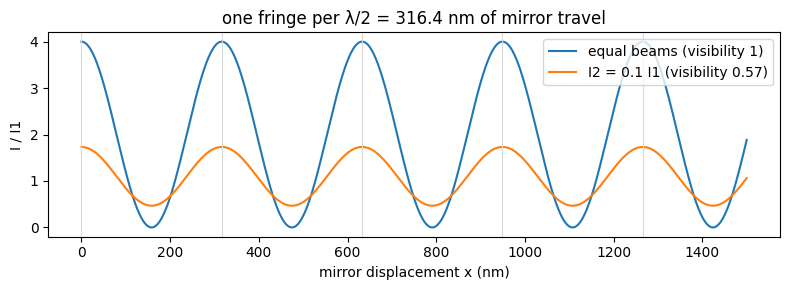

In [4]:
print("fringe rate - first-order Doppler shift =", L.fringe_rate_equals_doppler())
x = np.linspace(0, 1.5e-6, 1000)
fig, ax = plt.subplots(figsize=(8, 3))
for I2, lab in ((1.0, "equal beams (visibility 1)"), (0.1, "I2 = 0.1 I1 (visibility 0.57)")):
    ax.plot(x * 1e9, L.michelson_intensity(4 * np.pi * x / 632.8e-9, 1.0, I2), label=lab)
for m in range(5): ax.axvline(m * 316.4, color="0.85", lw=0.8)
ax.set_xlabel("mirror displacement x (nm)"); ax.set_ylabel("I / I1"); ax.legend(loc="upper right")
ax.set_title("one fringe per λ/2 = 316.4 nm of mirror travel"); plt.tight_layout(); plt.show()

Fringe **visibility** $V = (I_{max}-I_{min})/(I_{max}+I_{min}) = 2\sqrt{I_1I_2}/(I_1+I_2)$ drops when
the beams are unbalanced. That's why an LDV aimed at a dark, rough surface (weak return) has a weaker
signal, though even $I_2 = 0.1\,I_1$ keeps $V = 0.57$.

# 3. A vibrating mirror: Bessel functions appear

Let the mirror vibrate, $x(t) = a\sin\Omega t$. The interference phase becomes
$$\Delta\phi(t) = \phi_0 + b\sin\Omega t,\qquad b = \frac{4\pi a}{\lambda}$$
(the **modulation index**). The detector sees $\cos(\phi_0 + b\sin\Omega t)$. The **Jacobi–Anger
expansion** $e^{ib\sin\theta} = \sum_n J_n(b)\,e^{in\theta}$ splits this into harmonics of $\Omega$:
$$\cos(\phi_0 + b\sin\Omega t) = J_0(b)\cos\phi_0 + 2\sum_{k\ge1}J_{2k}(b)\cos(2k\Omega t)\cos\phi_0 - 2\sum_{k\ge1}J_{2k-1}(b)\sin\big((2k-1)\Omega t\big)\sin\phi_0 .$$

The even harmonics scale with $\cos\phi_0$ and the odd ones with $\sin\phi_0$. The bias point
$\phi_0$ (where the mirror sits on the fringe) decides which you see.

Jacobi-Anger series vs direct exp(i b sin x), b = 2:  max error = 7.947987303456223e-16


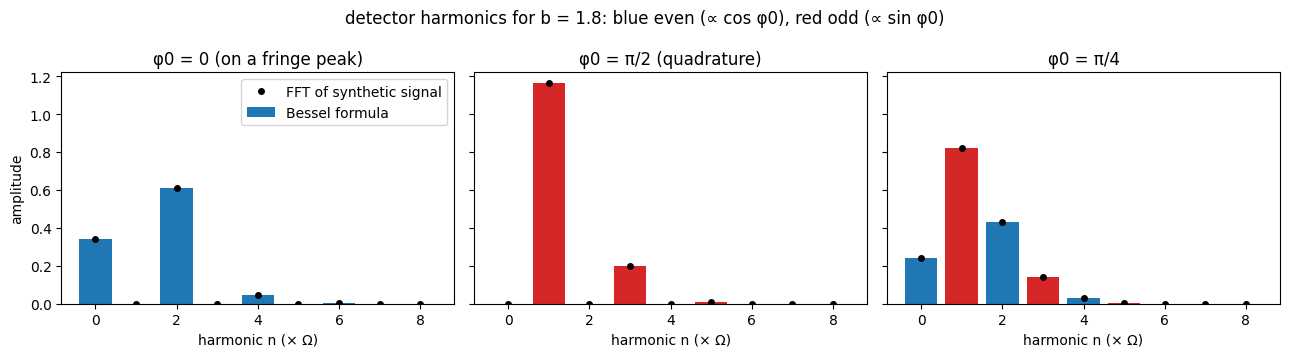

max |formula - FFT| = 2.220446049250313e-16


In [5]:
print("Jacobi-Anger series vs direct exp(i b sin x), b = 2:  max error =", L.jacobi_anger_check(2.0))
b = 1.8
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a_, (phi0, name) in zip(ax, ((0, "φ0 = 0 (on a fringe peak)"), (np.pi/2, "φ0 = π/2 (quadrature)"), (np.pi/4, "φ0 = π/4"))):
    ns, amp = L.detector_harmonics(b, phi0); _, fa = L.fft_harmonics(b, phi0)
    a_.bar(ns, amp, color=["C0" if n % 2 == 0 else "C3" for n in ns], label="Bessel formula")
    a_.plot(ns, fa, "ko", ms=4, label="FFT of synthetic signal")
    a_.set_title(name); a_.set_xlabel("harmonic n (× Ω)")
ax[0].set_ylabel("amplitude"); ax[0].legend()
plt.suptitle(f"detector harmonics for b = {b}: blue even (∝ cos φ0), red odd (∝ sin φ0)"); plt.tight_layout(); plt.show()
print("max |formula - FFT| =", max(np.max(np.abs(L.detector_harmonics(b, p)[1] - L.fft_harmonics(b, p)[1])) for p in (0, np.pi/2, np.pi/4)))

## 3.1 The Bessel-null method: measure nanometers with a zero

Choose the bias so the even terms show, and watch the DC (carrier) term $J_0(b)$ as the vibration
grows. It goes exactly to **zero** at the zeros of $J_0$: $b = 2.405,\ 5.520,\ 8.654,\ \dots$ A zero
is easy to find precisely, and it doesn't depend on laser power or detector gain. Each zero corresponds
to an exact amplitude $a = j_{0,m}\lambda/(4\pi)$, which is how primary vibration-calibration
standards work [2].

,zero of J0,vibration amplitude a (nm)
0,2.40483,121.10
1,5.52008,277.97
2,8.65373,435.77


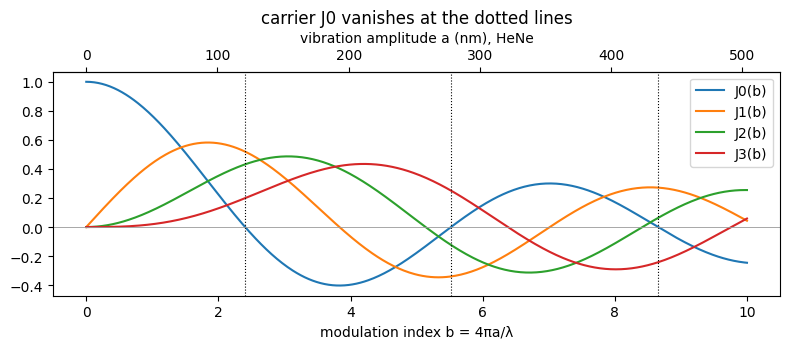

In [6]:
z, amps = L.bessel_null_amplitudes(3)
display(pd.DataFrame({"zero of J0": z.round(5), "vibration amplitude a (nm)": (amps * 1e9).round(2)}))
bb = np.linspace(0, 10, 500)
plt.figure(figsize=(8, 3.6))
for n in range(4): plt.plot(bb, jv(n, bb), label=f"J{n}(b)")
for zz in z: plt.axvline(zz, color="k", ls=":", lw=0.8)
plt.axhline(0, color="0.6", lw=0.6)
ax2 = plt.gca().secondary_xaxis("top", functions=(lambda q: q * 632.8 / (4*np.pi), lambda a: a * 4*np.pi / 632.8))
ax2.set_xlabel("vibration amplitude a (nm), HeNe")
plt.xlabel("modulation index b = 4πa/λ"); plt.legend(); plt.title("carrier J0 vanishes at the dotted lines"); plt.tight_layout(); plt.show()

The first null is a vibration of **121.1 nm**, about a fifth of a wavelength, read off a zero
crossing. This is the same Jacobi–Anger math as an electro-optic phase modulator's sidebands
([`pm_sideband_bessel`](../dgs/pm_sideband_bessel.py)). There the vibrating mirror is replaced by a
voltage-driven crystal.

# 4. A real LDV: heterodyne detection recovers $v(t)$

A plain Michelson can't tell toward from away, since $\cos$ is even. Commercial LDVs shift the
reference beam by $f_B$ (an acousto-optic Bragg cell, typically 40 MHz). The detector then sees
$$s(t) = \cos\big(2\pi f_B t + \Delta\phi(t)\big),$$
a carrier at $f_B$ that the Doppler shift pushes up or down. Demodulation:

1. Multiply by $e^{-i2\pi f_Bt}$, which moves the carrier to 0 Hz.
2. Low-pass filter to keep only the baseband.
3. Take the unwrapped angle to get $\Delta\phi(t)$.
4. Differentiate: $v = \frac{\lambda}{4\pi}\frac{d\Delta\phi}{dt}$.

Test: a surface vibrating at 5 kHz with 0.5 m/s peak velocity (peak Doppler shift 1.58 MHz, well inside
$f_B$), sampled at 200 MS/s, at several signal-to-noise ratios:

,SNR (dB),RMS velocity error (mm/s),relative to 0.354 m/s RMS
0,40,5.89,1.7%
1,30,18.62,5.3%
2,20,58.95,16.7%
3,10,188.18,53.2%


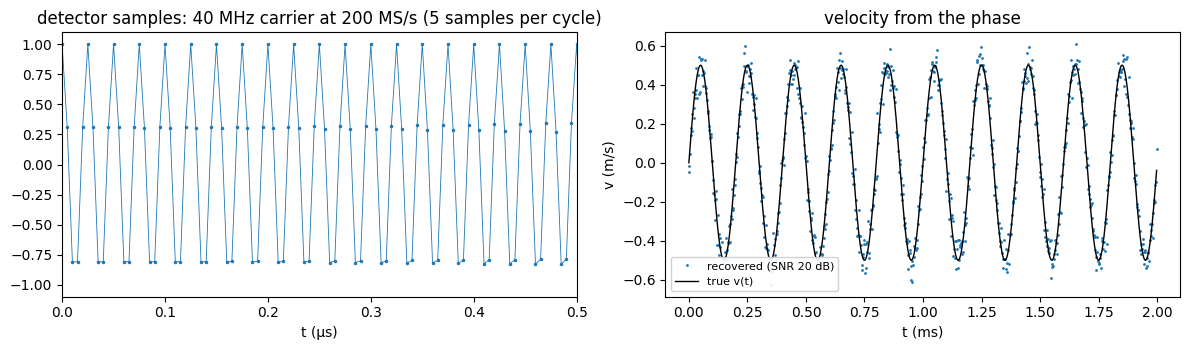

In [7]:
vel = lambda t: 0.5 * np.sin(2 * np.pi * 5e3 * t)
rows = []
for snr in (40, 30, 20, 10):
    r = L.heterodyne_ldv(vel, snr_db=snr)
    rows.append({"SNR (dB)": snr, "RMS velocity error (mm/s)": round(r["rms_error"] * 1e3, 2),
                 "relative to 0.354 m/s RMS": f"{r['rms_error'] / (0.5/np.sqrt(2)):.1%}"})
display(pd.DataFrame(rows))
r = L.heterodyne_ldv(vel, snr_db=20)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
n = 4000
ax[0].plot(r["t"][:n] * 1e6, np.cos(2*np.pi*40e6*r["t"][:n] + 4*np.pi*np.cumsum(r["v"])[:n]/200e6/632.8e-9), ".-", lw=0.6, ms=3)
ax[0].set_xlim(0, 0.5); ax[0].set_xlabel("t (µs)"); ax[0].set_title("detector samples: 40 MHz carrier at 200 MS/s (5 samples per cycle)")
s = slice(None, None, 500)
ax[1].plot(r["t"][s] * 1e3, r["v_rec"][s], ".", ms=2, label="recovered (SNR 20 dB)")
ax[1].plot(r["t"][s] * 1e3, r["v"][s], "k", lw=1, label="true v(t)")
ax[1].set_xlabel("t (ms)"); ax[1].set_ylabel("v (m/s)"); ax[1].legend(loc="lower left", fontsize=8, framealpha=0.9); ax[1].set_title("velocity from the phase")
plt.tight_layout(); plt.show()

The error falls by $\sqrt{10}\approx3.2\times$ per 10 dB of SNR, so it scales as $1/\sqrt{\text{SNR}}$:
phase noise is the noise amplitude divided by the signal amplitude. The Bragg shift is what makes the
sign of $v$ measurable. Without it, $\pm v$ give identical detector signals.

# 5. Bessel functions in diffraction: the Airy pattern

A circular aperture of radius $R$ is a continuum of point sources interfering. In the far field, the
amplitude at angle $\theta$ is the aperture integral
$\int_0^R\!\!\int_0^{2\pi} e^{-iqr\cos\varphi}\,r\,d\varphi\,dr$, with $q = k\sin\theta$.

* The angle integral is the integral form of a Bessel function: $2\pi J_0(qr)$.
* The radial integral uses $\frac{d}{du}[uJ_1(u)] = uJ_0(u)$:

In [8]:
radial, check = L.airy_symbolic()
display(Math(r"\int_0^R J_0(qr)\,r\,dr = " + sp.latex(radial) + r"\qquad(\text{check: } " + sp.latex(check) + ")"))
display(Math(r"I(\theta) = I_0\left[\frac{2J_1(x)}{x}\right]^2,\quad x = kR\sin\theta"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

So $I = I_0[2J_1(x)/x]^2$. The first dark ring is the first zero of $J_1$, $x = 3.8317$, giving
$\sin\theta = 3.8317/(kR) = 1.22\,\lambda/D$: the **Rayleigh resolution limit** of every lens, telescope
and microscope. Below we check the formula against a brute-force 2D FFT of a pixelated disk (the FFT
is the Fraunhofer integral):

Rayleigh factor j_(1,1)/pi = 1.2197;  max |FFT - Airy| = 0.0036


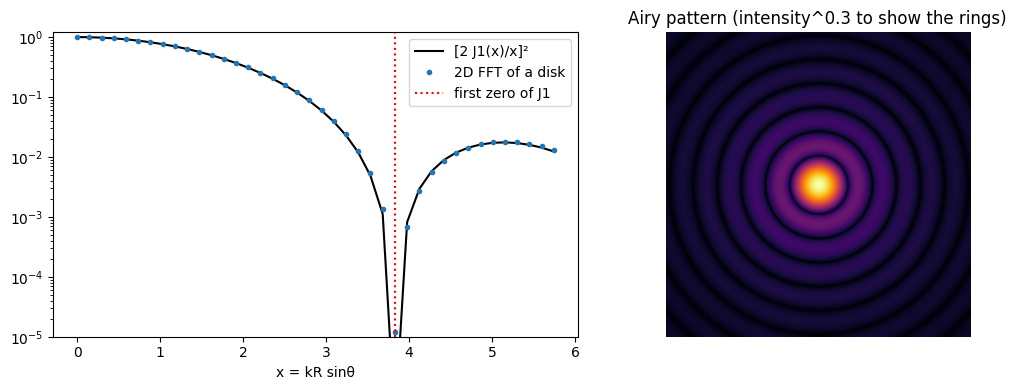

In [9]:
x, P, A = L.airy_numeric_check()
print(f"Rayleigh factor j_(1,1)/pi = {L.rayleigh_factor():.4f};  max |FFT - Airy| = {np.max(np.abs(P - A)):.4f}")
yy, xx = np.mgrid[-200:200, -200:200] / 30
rr = np.hypot(xx, yy) * 3
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(x, A, "k", label="[2 J1(x)/x]²"); ax[0].plot(x, P, "o", ms=3, label="2D FFT of a disk")
ax[0].axvline(3.8317, color="r", ls=":", label="first zero of J1"); ax[0].set_yscale("log"); ax[0].set_ylim(1e-5, 1.2)
ax[0].set_xlabel("x = kR sinθ"); ax[0].legend()
ax[1].imshow(L.airy(rr) ** 0.3, cmap="inferno"); ax[1].set_axis_off(); ax[1].set_title("Airy pattern (intensity^0.3 to show the rings)")
plt.tight_layout(); plt.show()

# 6. The same vibrometer in a hardware-style demodulator, CUDA, and MATLAB

The FFT filter in §4 needs the whole record at once. Real-time demodulators (FPGA, GPU) instead
filter with **cascaded moving averages**, called a CIC filter. A 5-sample boxcar at 200 MS/s has a null at
every multiple of 40 MHz, so the $2f_B = 80$ MHz mixing product lands on a null. The Doppler shift
moves it slightly *off* the null, so one boxcar leaks about 2.6 %. Three in cascade leak about
$0.026^3\approx2\times10^{-5}$:

In [10]:
t, s, v = L.vibration_signal(400_000, 0.5)
rows = []
for order in (1, 2, 3):
    vr, d = L.cic_demodulate(s, order=order); d = int(d)
    e = vr[d:] - v[:len(v) - d]
    rows.append({"boxcars in cascade": order, "group delay (samples)": d,
                 "noise-free RMS error (m/s)": f"{np.sqrt(np.nanmean(e**2)):.2e}"})
pd.DataFrame(rows)

,boxcars in cascade,group delay (samples),noise-free RMS error (m/s)
0,1,2,7.77e-02
1,2,4,1.76e-03
2,3,6,4.21e-05


Three implementations of the same order-3 CIC demodulator:

* **Python** (`cic_demodulate`), the reference.
* **CUDA** ([`hardware/cuda_ldv/ldv_demod.cu`](../hardware/cuda_ldv/ldv_demod.cu)). It demodulates
  $C$ channels at once, as a *scanning* vibrometer measuring many surface points would. Mixing, the
  13-tap FIR and `atan2` use one thread per sample. Phase unwrapping is a running sum along time, so
  it gets one thread per **channel**. Build with `nvcc -O2 -o ldv_demod.exe ldv_demod.cu` (x64 Native Tools prompt).
* **MATLAB** ([`learn/matlab/ldv_vibrometer.m`](../learn/matlab/ldv_vibrometer.m)). It uses `filter`,
  `unwrap(angle(z))`, `besselj` and `fzero`, and writes `ldv_matlab.csv`.

Noise-free, all three must agree to roundoff. With noise they use different random generators, so
they should agree **statistically**.

In [11]:
import subprocess
ROOT = pathlib.Path.cwd().parent
cu = ROOT / "hardware" / "cuda_ldv"; exe = cu / "ldv_demod.exe"
res = {}
vr, _ = L.cic_demodulate(s); e = vr[6:] - v[:-6]; res["Python noise-free"] = np.sqrt(np.nanmean(e**2))
rng = np.random.default_rng(0)
vr, _ = L.cic_demodulate(s + np.sqrt(0.5) * 10**(-30/20) * rng.standard_normal(len(s)))
e = vr[6:] - v[:-6]; res["Python SNR 30 dB"] = np.sqrt(np.nanmean(e**2))
if exe.exists():
    print(subprocess.run([str(exe), "1", "400000", "-1"], capture_output=True, text=True, cwd=str(cu)).stdout.strip())
    last = np.loadtxt(cu / "ldv_last_channel.csv", delimiter=",", skiprows=1)
    vr, _ = L.cic_demodulate(s)
    print(f"CUDA vs Python, sample by sample (noise-free): max diff = {np.max(np.abs(last[:, 1] - vr[last[:, 0].astype(int)])):.1e} m/s")
    res["CUDA noise-free"] = np.loadtxt(cu / "ldv_rms.csv", delimiter=",", skiprows=1, ndmin=2)[-1, 2]
    print(subprocess.run([str(exe), "256", "100000", "30"], capture_output=True, text=True, cwd=str(cu)).stdout.strip())
    r256 = np.loadtxt(cu / "ldv_rms.csv", delimiter=",", skiprows=1)
    res["CUDA SNR 30 dB (256 channels, mean)"] = r256[:, 2].mean()
else:
    print("ldv_demod.exe not built; see the build line above.")
mcsv = ROOT / "learn" / "matlab" / "ldv_matlab.csv"
if mcsv.exists():
    m = pd.read_csv(mcsv).set_index("metric")["value"]
    res["MATLAB noise-free"] = m["cic_rms_snr_Inf"]; res["MATLAB SNR 30 dB"] = m["cic_rms_snr_30"]
    print("MATLAB null amplitudes (nm):", m[[f"null_amplitude_nm_{k}" for k in (1, 2, 3)]].round(2).tolist(),
          " Python:", (L.bessel_null_amplitudes(3)[1] * 1e9).round(2).tolist())
pd.DataFrame({"RMS velocity error (m/s)": res}).style.format("{:.4e}")

C=1 N=400000 snr_db=-1  demod_ms=5.54 unwrap_ms=254.83  samples_per_s=1.536e+06
channel 0: v_peak=0.5000 m/s  rms_error=4.2053e-05 m/s
CUDA vs Python, sample by sample (noise-free): max diff = 6.3e-12 m/s


C=256 N=100000 snr_db=30  demod_ms=521.44 unwrap_ms=81.35  samples_per_s=4.247e+07
channel 255: v_peak=0.5000 m/s  rms_error=2.8723e-02 m/s
MATLAB null amplitudes (nm): [121.1, 277.97, 435.77]  Python: [121.1, 277.97, 435.77]


,RMS velocity error (m/s)
Python noise-free,4.2053e-05
Python SNR 30 dB,2.8635e-02
CUDA noise-free,4.2053e-05
"CUDA SNR 30 dB (256 channels, mean)",2.8313e-02
MATLAB noise-free,4.2053e-05
MATLAB SNR 30 dB,2.8500e-02


**Reading the CUDA timing.** With one channel, unwrapping takes most of the time: it is a
sequential running sum, and a single GPU thread is slow. With 256 channels that step runs in parallel,
and synthesis plus filtering (one thread per sample) dominates instead. Amdahl's law in one program:
the sequential part limits you until there are enough independent channels to fill the GPU. A
parallel prefix scan over the phase jumps would remove that limit.

At SNR 30 dB the CIC error (about 0.029 m/s) is higher than the FFT filter's in §4 (about 0.019 m/s).
The CIC passband is wider than the FFT method's 10 MHz cut, so it lets in more noise. That is the price
of a filter that runs sample by sample in real time.

The small residual comes from approximating a circle with pixels. Its edge is a staircase, which
slightly reshapes the faint outer rings.

# Summary

| topic | where it shows up | check |
|---|---|---|
| Doppler, moving mirror | $f' = f(1+\beta)/(1-\beta)$, $\Delta f = 2v/\lambda$ | SymPy series; 3.16 MHz at 1 m/s |
| relativistic correction | $2\beta^2 f \approx 0.01$ Hz at 1 m/s | below float64 roundoff, so exact only |
| interference | fringe rate $=$ Doppler beat | SymPy, any $x(t)$ |
| constructive / destructive | $(\sqrt{I_1}\pm\sqrt{I_2})^2$, visibility | plot |
| Bessel (Jacobi–Anger) | vibration harmonics $\propto J_n(b)$ | formula = FFT to $10^{-16}$ |
| Bessel null | $J_0(b)=0 \Rightarrow a = 121.1$ nm | table |
| heterodyne LDV | $v(t)$ from phase, error $\propto 1/\sqrt{\text{SNR}}$ | synthetic signal |
| Bessel in diffraction | Airy $[2J_1(x)/x]^2$, $1.22\lambda/D$ | SymPy integral + 2D FFT |
| CIC demodulator | Python = CUDA = MATLAB | noise-free to roundoff, noisy statistically |

## Exercises
1. A loudspeaker cone shows its first carrier null at a drive of 2.0 V. Assuming amplitude ∝ voltage, what drive gives the second null, and what is the amplitude there?
2. At which bias $\phi_0$ is the first harmonic largest? Why do vibrometers without a Bragg cell try to sit there (quadrature)?
3. With $f_B = 40$ MHz and HeNe light, what is the largest surface speed the heterodyne LDV can measure before the sign becomes ambiguous?
4. A smartphone camera lens has $D = 2$ mm. What is its diffraction-limited angular resolution at 550 nm? Compare with the pixel pitch angle.
5. Replace the circular aperture with an annulus (a telescope with a central mirror obstruction). Predict, then compute with the FFT, what happens to the central peak and the first ring.